# Crop Yield Prediction using Machine Learning

Random Forest vs Decision Tree regression on the Indian crop yield dataset (`data/crop_yield.csv`, 19,689 records, 55 crops, 30 states, 1997-2020).

**Steps:** load data → one-hot encode Crop, Season, State → 80/20 train/test split → train models → evaluate with MSE and R-squared → plots.

Random Forest Results:
Mean Squared Error: 10346.65314466047
R-squared: 0.9870866970082096

Decision Tree Results:
Mean Squared Error: 19080.069990686818
R-squared: 0.9761868189211063


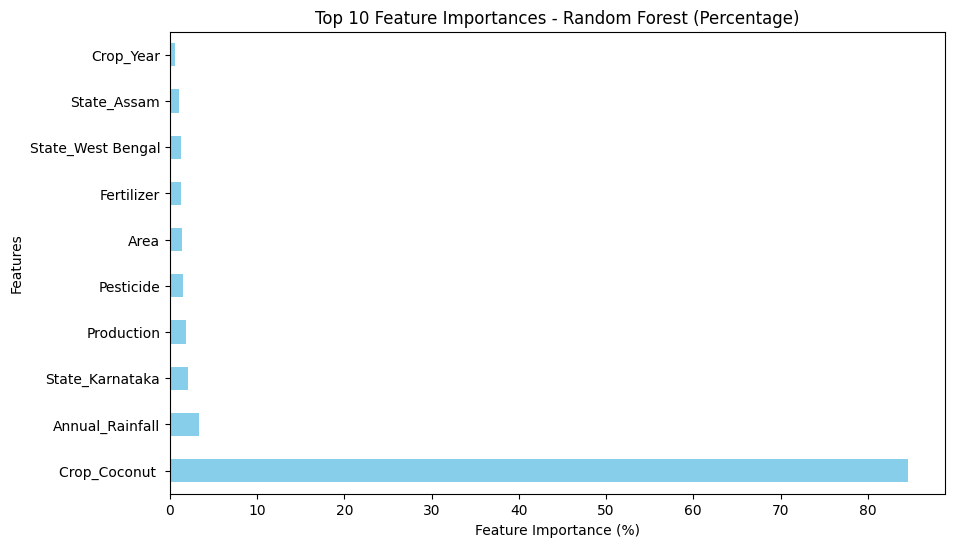

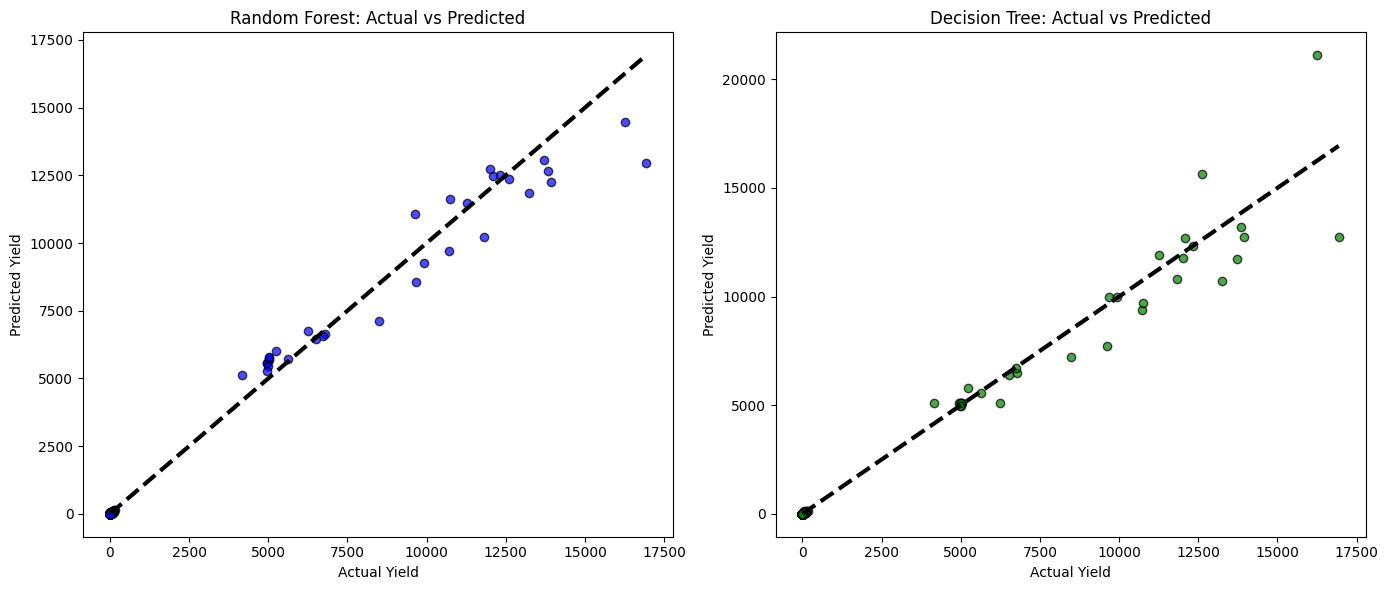

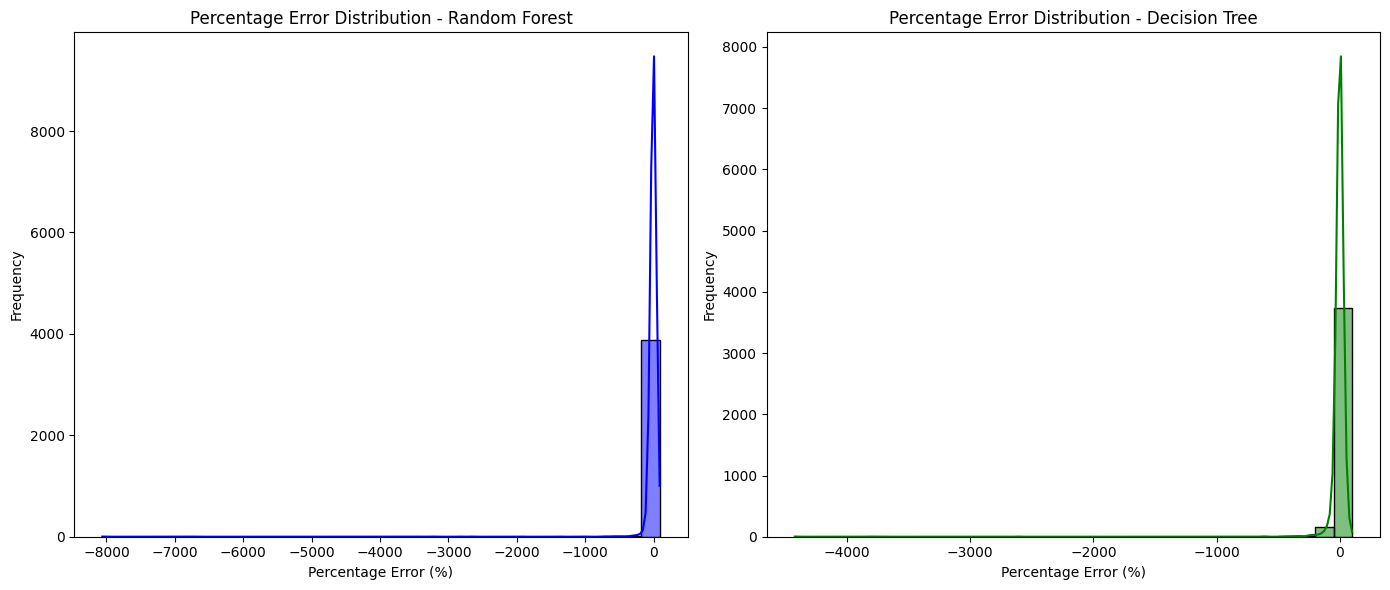

In [ ]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Load the dataset
# Dataset location: works in Google Colab (upload crop_yield.csv to /content) and from a cloned repo
import os
file_path = next(p for p in ('data/crop_yield.csv', 'crop_yield.csv', '/content/crop_yield.csv') if os.path.exists(p))
data = pd.read_csv(file_path)

# Identify categorical columns and numerical columns
categorical_columns = ['Crop', 'Season', 'State']
numerical_columns = ['Crop_Year', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']

# Apply OneHotEncoding for categorical columns
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False, drop='first')
encoded_categorical = pd.DataFrame(encoder.fit_transform(data[categorical_columns]))
encoded_categorical.columns = encoder.get_feature_names_out(categorical_columns)

# Combine encoded categorical data with the numerical data
X = pd.concat([encoded_categorical, data[numerical_columns]], axis=1)
y = data['Yield']

# Split the data into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the models
rf_model = RandomForestRegressor(random_state=42)
dt_model = DecisionTreeRegressor(random_state=42)

# Train the models
rf_model.fit(X_train, y_train)
dt_model.fit(X_train, y_train)

# Make predictions using both models
rf_predictions = rf_model.predict(X_test)
dt_predictions = dt_model.predict(X_test)

# Evaluate the models using Mean Squared Error and R-squared
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_r2 = r2_score(y_test, rf_predictions)
dt_mse = mean_squared_error(y_test, dt_predictions)
dt_r2 = r2_score(y_test, dt_predictions)

# Print the results
print("Random Forest Results:")
print(f"Mean Squared Error: {rf_mse}")
print(f"R-squared: {rf_r2}")

print("\nDecision Tree Results:")
print(f"Mean Squared Error: {dt_mse}")
print(f"R-squared: {dt_r2}")

# ------- Graphical Representations with Percentages -------

# 1. Feature Importance Plot for Random Forest (with percentages)
plt.figure(figsize=(10, 6))
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
# Convert to percentages
feature_importances_percentage = (feature_importances / feature_importances.sum()) * 100
feature_importances_percentage.nlargest(10).plot(kind='barh', color='skyblue')
plt.title('Top 10 Feature Importances - Random Forest (Percentage)')
plt.xlabel('Feature Importance (%)')
plt.ylabel('Features')
plt.show()

# 2. Prediction vs Actual Values for both models (with percentage difference)
plt.figure(figsize=(14, 6))

# Random Forest
plt.subplot(1, 2, 1)
plt.scatter(y_test, rf_predictions, color='blue', edgecolor='k', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=3)
plt.title('Random Forest: Actual vs Predicted')
plt.xlabel('Actual Yield')
plt.ylabel('Predicted Yield')

# Decision Tree
plt.subplot(1, 2, 2)
plt.scatter(y_test, dt_predictions, color='green', edgecolor='k', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=3)
plt.title('Decision Tree: Actual vs Predicted')
plt.xlabel('Actual Yield')
plt.ylabel('Predicted Yield')

plt.tight_layout()
plt.show()

# 3. Percentage Error Distribution for both models
plt.figure(figsize=(14, 6))

# Calculate percentage error
rf_percentage_error = 100 * (y_test - rf_predictions) / y_test
dt_percentage_error = 100 * (y_test - dt_predictions) / y_test

# Random Forest
plt.subplot(1, 2, 1)
sns.histplot(rf_percentage_error, bins=30, kde=True, color='blue')
plt.title('Percentage Error Distribution - Random Forest')
plt.xlabel('Percentage Error (%)')
plt.ylabel('Frequency')

# Decision Tree
plt.subplot(1, 2, 2)
sns.histplot(dt_percentage_error, bins=30, kde=True, color='green')
plt.title('Percentage Error Distribution - Decision Tree')
plt.xlabel('Percentage Error (%)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

